In [1]:
# Llama-3.2 is gated. Store a Kaggle secret named HF_TOKEN.
from kaggle_secrets import UserSecretsClient
from huggingface_hub import login

try:
    token = UserSecretsClient().get_secret('HF_TOKEN')
    login(token=token)
    print('Hugging Face login: OK')
except Exception as exc:
    print('HF login was not completed automatically:', exc)
    print('If the model is already cached and accessible, you can continue.')


Hugging Face login: OK


In [2]:
import torch
from transformers import AutoModelForCausalLM
import matplotlib.pyplot as plt

model = AutoModelForCausalLM.from_pretrained('meta-llama/Llama-3.2-1B',)

config.json:   0%|          | 0.00/843 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 2.47GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/146 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/185 [00:00<?, ?B/s]

In [3]:
# TODO for Question 4
"""

Hint:
# Analyze the weights of the query projection layer (q_proj) where layer = k
 q_weight = model.model.layers[k].self_attn.q_proj.weight.detach()

# Apply SVD to decompose the weight matrix into U (left singular vectors), S (singular values), and V (right singular vectors).
 U, S, Vh = torch.linalg.svd(q_weight.float(), full_matrices=False)

# Compute the retained energy ratio (Cumulative energy) of each singular value.
energy_ratios = torch.cumsum(S ** 2, dim=0) / torch.sum(S ** 2) * 100
"""


'\n\nHint:\n# Analyze the weights of the query projection layer (q_proj) where layer = k\n q_weight = model.model.layers[k].self_attn.q_proj.weight.detach()\n\n# Apply SVD to decompose the weight matrix into U (left singular vectors), S (singular values), and V (right singular vectors).\n U, S, Vh = torch.linalg.svd(q_weight.float(), full_matrices=False)\n\n# Compute the retained energy ratio (Cumulative energy) of each singular value.\nenergy_ratios = torch.cumsum(S ** 2, dim=0) / torch.sum(S ** 2) * 100\n'

Layer 0: Minimum target rank for >= 50% energy = 62


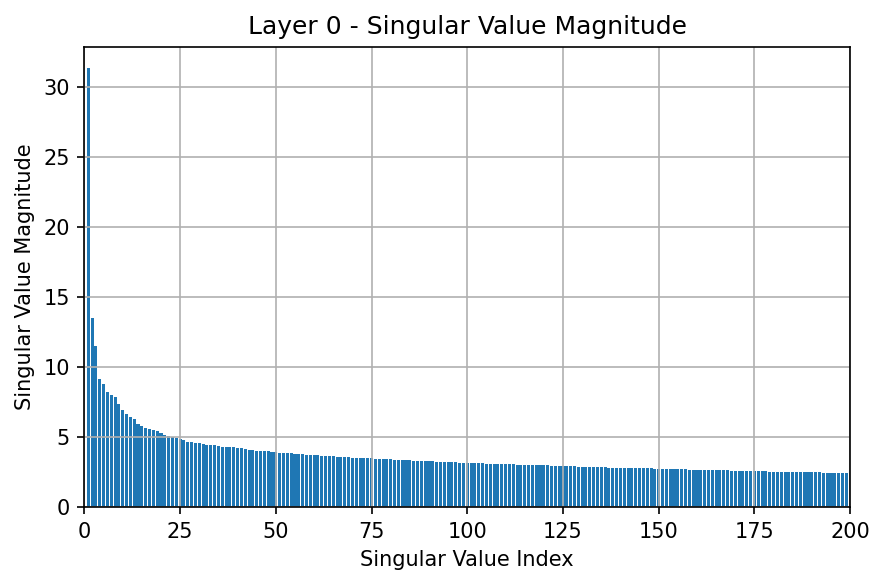

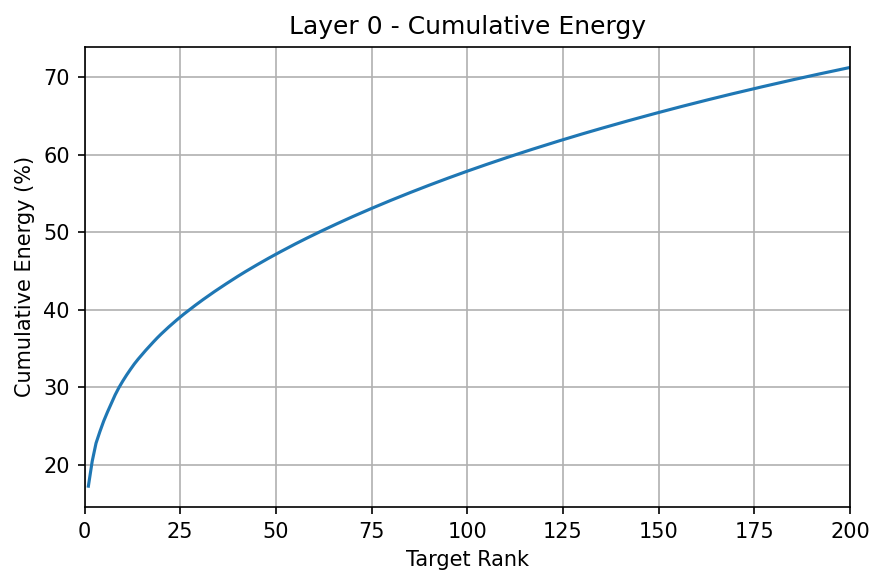

Layer 7: Minimum target rank for >= 50% energy = 120


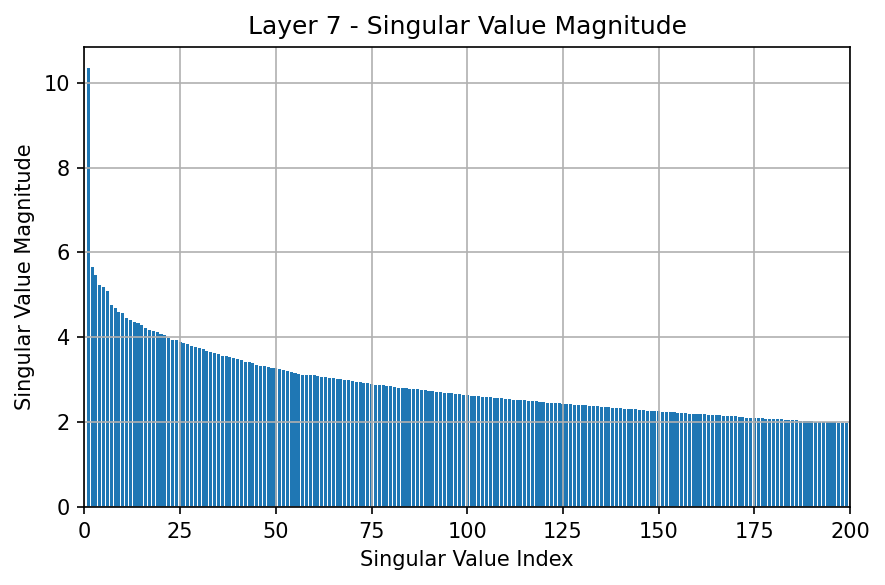

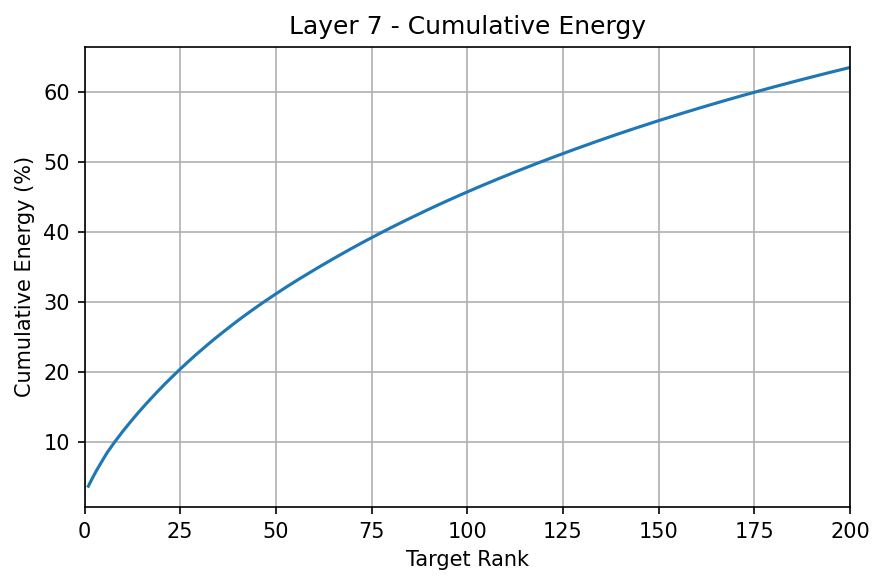

Layer 15: Minimum target rank for >= 50% energy = 84


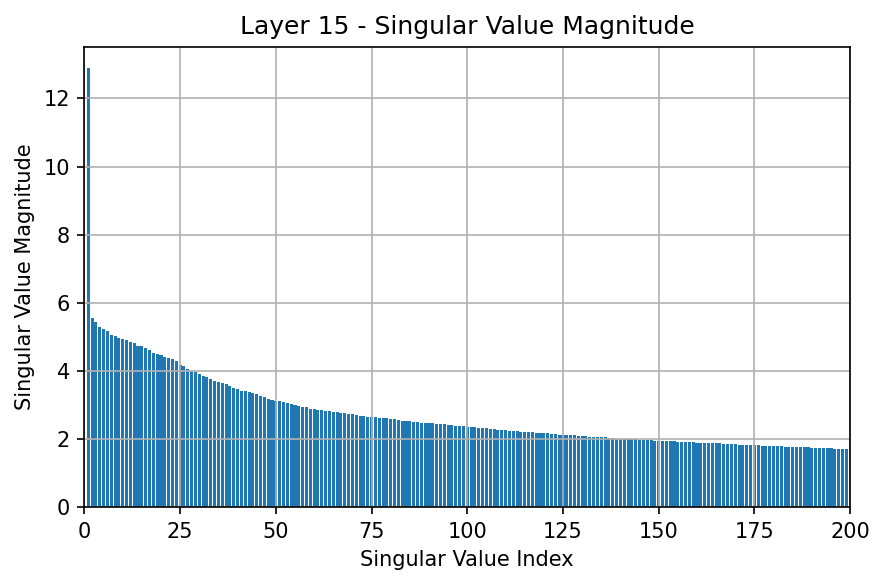

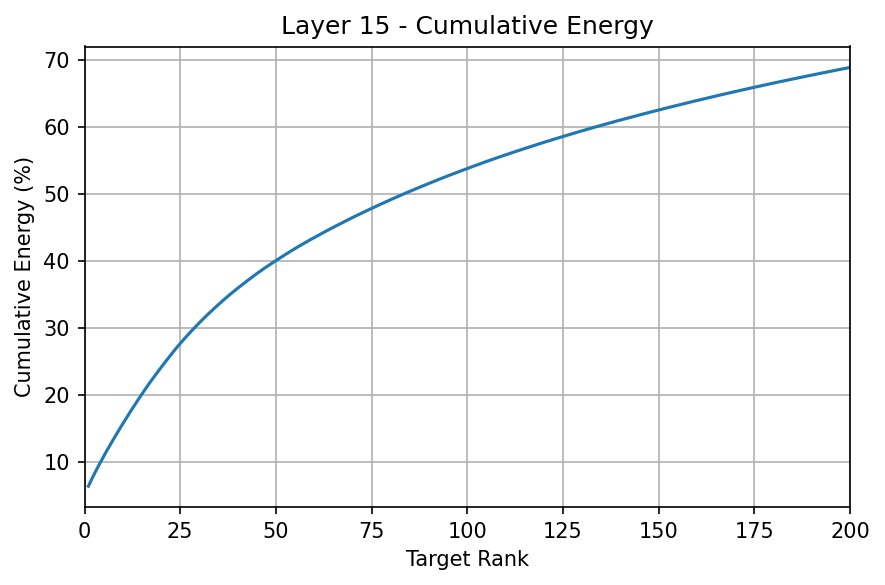

In [4]:
import matplotlib.pyplot as plt

target_layers = [0, 7, 15]

for layer_idx in target_layers:
    # 1. Extract query projection weights and apply SVD
    q_weight = model.model.layers[layer_idx].self_attn.q_proj.weight.detach()
    U, S, Vh = torch.linalg.svd(q_weight.float(), full_matrices=False)
    
    # 2. Compute cumulative energy percentage
    energy_ratios = torch.cumsum(S ** 2, dim=0) / torch.sum(S ** 2) * 100
    
    # 3. Find and print the minimum target rank for >= 50% energy
    min_target_rank = (energy_ratios >= 50.0).nonzero()[0].item() + 1
    print(f"Layer {layer_idx}: Minimum target rank for >= 50% energy = {min_target_rank}")
    
    # Slice the first 200 components and convert to NumPy for plotting
    S_top200 = S[:200].cpu().numpy()
    energy_top200 = energy_ratios[:200].cpu().numpy()
    x_indices = range(1, 201)
    
    # 4. Chart 1: Singular Value Magnitude (Bar Chart)
    plt.figure(figsize=(6, 4), dpi=150)
    plt.bar(x_indices, S_top200, color='#1f77b4', width=0.8)
    plt.title(f'Layer {layer_idx} - Singular Value Magnitude')
    plt.xlabel('Singular Value Index')
    plt.ylabel('Singular Value Magnitude')
    plt.xlim(0, 200)
    plt.grid(True)
    plt.tight_layout()
    plt.savefig(f'layer_{layer_idx}_sv_magnitude.png')
    plt.show()
    
    # 5. Chart 2: Cumulative Energy (%) (Line Chart)
    plt.figure(figsize=(6, 4), dpi=150)
    plt.plot(x_indices, energy_top200, color='#1f77b4', linewidth=1.5)
    plt.title(f'Layer {layer_idx} - Cumulative Energy')
    plt.xlabel('Target Rank')
    plt.ylabel('Cumulative Energy (%)')
    plt.xlim(0, 200)
    plt.grid(True)
    plt.tight_layout()
    plt.savefig(f'layer_{layer_idx}_cumulative_energy.png')
    plt.show()